# EDA — anonymised crowdsensed WiFi corpus

Companion notebook for IEEE Latin America Transactions manuscript **ID 11172**.

- **Input:** `../data/datos_wifi_curated_anon.parquet`
- **QC:** `../data/qc_report.json`
- **Figures:** `../reports/figures/` (created on demand; relative paths only)

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
DATA = ROOT / "data" / "datos_wifi_curated_anon.parquet"
QC = ROOT / "data" / "qc_report.json"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
FIG_REL = FIG.relative_to(ROOT).as_posix()

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

df = pd.read_parquet(DATA)
qc = json.loads(QC.read_text(encoding="utf-8"))
print(
    f"Rows: {len(df):,} | BSSIDs: {df['bssid'].nunique():,} | "
    f"auditors: {df['device_id'].nunique():,}"
)
print("QC curated_rows:", qc.get("curated_rows"), "| input:", qc.get("input"))
print("Figure directory:", FIG_REL)

Rows: 53,371 | BSSIDs: 36,010 | auditors: 27
QC curated_rows: 53371 | input: data/datos_wifi_curated_anon.parquet
Figure directory: reports/figures


## Descriptive statistics

In [2]:
display(df[["level", "frequency", "estimated_distance", "distance_residual"]].describe())
print("Municipalities:", df["municipality"].nunique())
print("Security classes:\n", df["security_type_parsed"].value_counts().head(10))

,level,frequency,estimated_distance,distance_residual
count,53371.000000,53371.000000,53371.000000,5.337100e+04
mean,-82.620768,3814.094396,15.628563,1.967146e-01
std,9.758142,1521.915005,11.546910,4.081573e+00
min,-99.000000,2412.000000,0.076862,-4.985718e+01
25%,-89.000000,2437.000000,8.208914,0.000000e+00
50%,-84.000000,2462.000000,12.181879,0.000000e+00
75%,-77.000000,5300.000000,19.306977,4.440892e-16
max,-13.000000,5825.000000,63.095734,5.413548e+01


Municipalities: 45
Security classes:
 security_type_parsed
WPA2    48567
OPEN     4749
WPA        49
WEP         6
Name: count, dtype: int64


## RSSI and heuristic exposure

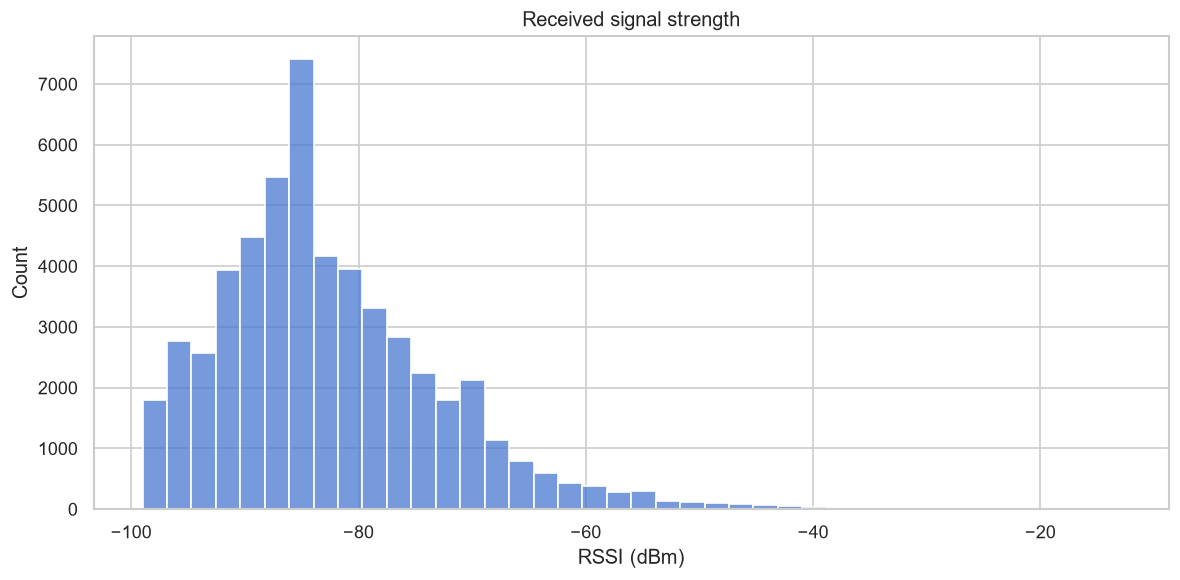

threat_type_heuristic
EVIL_TWIN_CANDIDATE     9496
OPEN_NETWORK            2096
WEP_NETWORK_DETECTED       6
Name: count, dtype: int64
Heuristic exposure rate: 0.2173090255007401


In [3]:
fig, ax = plt.subplots()
sns.histplot(df["level"], bins=40, ax=ax)
ax.set_xlabel("RSSI (dBm)")
ax.set_title("Received signal strength")
fig.tight_layout()
fig.savefig(FIG / "rssi_hist.png")
plt.show()

if "threat_type_heuristic" in df.columns:
    print(df["threat_type_heuristic"].value_counts())
if "is_anomaly_heuristic" in df.columns:
    print("Heuristic exposure rate:", float(df["is_anomaly_heuristic"].mean()))

## Auditor map

Auditor GPS points on an Esri street basemap, clipped to the Chiapas study region
(3-decimal coordinate rounding).


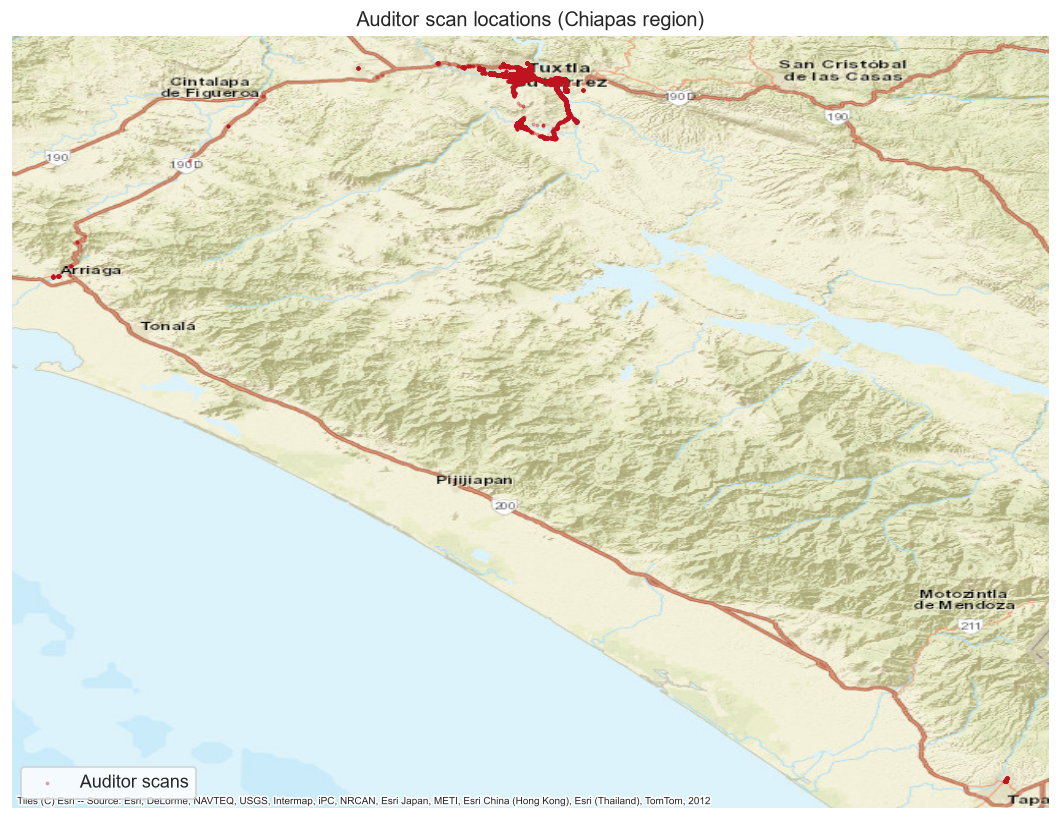

Mapped 48,501 / 53,371 points in-region | Saved: reports/figures/auditor_map.png


In [4]:
import warnings
import contextily as cx
from pyproj import Transformer

geo = df.dropna(subset=["latitude", "longitude"]).copy()
# Focus on the Chiapas study region (exclude rare GPS outliers)
region = geo[
    geo["latitude"].between(14.8, 17.9)
    & geo["longitude"].between(-94.3, -90.2)
].copy()
to_web = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
x, y = to_web.transform(region["longitude"].to_numpy(), region["latitude"].to_numpy())

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(x, y, s=5, alpha=0.4, c="#c1121f", linewidths=0, zorder=3, label="Auditor scans")
pad = 8_000
ax.set_xlim(float(np.min(x)) - pad, float(np.max(x)) + pad)
ax.set_ylim(float(np.min(y)) - pad, float(np.max(y)) + pad)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cx.add_basemap(
        ax,
        source=cx.providers.Esri.WorldStreetMap,
        attribution_size=6,
    )
ax.set_axis_off()
ax.set_title("Auditor scan locations (Chiapas region)")
ax.legend(loc="lower left", frameon=True)
fig.tight_layout()
fig.savefig(FIG / "auditor_map.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    f"Mapped {len(region):,} / {len(geo):,} points in-region | "
    f"Saved: {FIG_REL}/auditor_map.png"
)
